# 06_04 The Common Tests: t-tests, Chi-square Tests and ANOVA

**Learning objectives**
- Compare **two means** with the **Welch** (and pooled) two-sample $t$-test, and two **paired** measurements with the paired $t$-test.
- Test **counts** with the **chi-square** goodness-of-fit and independence tests, and measure the strength of association (**Cramer's V**).
- Compare **several means** with **one-way ANOVA** and the **$F$ test**, and see the sums-of-squares decomposition behind it.
- Know each test's **assumptions**, an **effect-size** measure to go with it, and how to pick the right test.

**Prerequisites:** [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb), [02_08 Student's t, chi-square and F](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb), [05_03 Sampling distributions](../../module_05_sampling/notebooks/05_03_sampling_distributions_standard_error.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math

## 2. Prerequisite recap

- A test needs a **statistic** with a known **null distribution**, a **p-value** and a decision at level $\alpha$ (06_03).
- The sample mean has $\mathrm{Var}(\bar X)=\sigma^2/n$; for independent samples the variances of the two means **add**: $\mathrm{Var}(\bar X_1-\bar X_2)=\sigma_1^2/n_1+\sigma_2^2/n_2$.
- Student's $t_\nu$, the chi-square $\chi^2_\nu$ and the $F_{\nu_1,\nu_2}$ distributions: the ratio of a Normal to the square root of an independent $\chi^2_\nu/\nu$ is a $t_\nu$; the ratio of two independent $\chi^2/\nu$ is an $F$ (02_08).
- **Contingency tables** and expected counts under independence (0a_04).

## 3. Intuition and story

Most real questions are comparisons: *do two couriers differ in delivery time? did training change performance? does the plan type affect churn? do three landing pages earn different revenue?* The tests of this lesson answer them by the same logic as 06_03: compute how far the observed difference is from "no difference" **in units of its own noise**, and look the result up in a known distribution.

| Question | Data | Test | Statistic |
|---|---|---|---|
| Do two groups have the same mean? | two independent samples | **Welch $t$-test** | difference / its standard error |
| Did the same units change? | paired measurements | **paired $t$-test** | mean difference / its standard error |
| Are counts distributed as claimed? | one categorical sample | **chi-square goodness of fit** | $\sum(O-E)^2/E$ |
| Are two categorical variables related? | contingency table | **chi-square independence** | $\sum(O-E)^2/E$ |
| Do several groups have the same mean? | $k$ independent samples | **one-way ANOVA** | $F$ = between-group / within-group variance |

## 4. Formal definitions

**Welch two-sample $t$-test** ($H_0:\mu_1=\mu_2$): $t=\dfrac{\bar x_1-\bar x_2}{\sqrt{s_1^2/n_1+s_2^2/n_2}}$ with Satterthwaite degrees of freedom $\nu=\dfrac{(s_1^2/n_1+s_2^2/n_2)^2}{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_2^2/n_2)^2}{n_2-1}}$. The **pooled** version assumes $\sigma_1=\sigma_2$: $s_p^2=\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}$, $t=\frac{\bar x_1-\bar x_2}{s_p\sqrt{1/n_1+1/n_2}}$, $\nu=n_1+n_2-2$.

**Paired $t$-test:** compute the differences $d_i$ and apply the one-sample test: $t=\dfrac{\bar d}{s_d/\sqrt n}$, $\nu=n-1$.

**Chi-square test:** $\chi^2=\sum\dfrac{(O_i-E_i)^2}{E_i}$. Goodness of fit: $E_i=np_i$, $\nu=K-1$ (minus one more for each estimated parameter). Independence in an $r\times c$ table: $E_{ij}=\dfrac{\text{row}_i\times\text{col}_j}{n}$, $\nu=(r-1)(c-1)$. Strength: $V=\sqrt{\dfrac{\chi^2}{n\,\min(r-1,c-1)}}$.

**One-way ANOVA** ($k$ groups, $N$ observations): $SST=SSB+SSW$ with $SSB=\sum n_j(\bar x_j-\bar x)^2$, $SSW=\sum\sum(x_{ij}-\bar x_j)^2$; $F=\dfrac{SSB/(k-1)}{SSW/(N-k)}\sim F_{k-1,N-k}$ under $H_0$. Effect size $\eta^2=SSB/SST$.

**Effect sizes:** Cohen's $d=\dfrac{\bar x_1-\bar x_2}{s_p}$ (0.2 small, 0.5 medium, 0.8 large).

## 5. Derivations

### 5.1 The two-sample $t$ statistic
$\bar X_1-\bar X_2$ is (approximately) Normal with mean $\mu_1-\mu_2$ and variance $\sigma_1^2/n_1+\sigma_2^2/n_2$ because independent variances add. Replacing the variances by $s_1^2,s_2^2$ and dividing gives a statistic close to $t$; the Satterthwaite formula picks the degrees of freedom so that the **scaled sum of the two variance estimates** matches a chi-square variable in mean and variance. **In plain words.** The difference of means, measured in units of its own estimated noise; the odd degrees of freedom reflect that the noise is itself estimated from two samples.

### 5.2 Why Welch is the safe default
The pooled test is exact when the variances are equal, but when the variances differ **and the sample sizes differ**, its standard error is wrong: with the *smaller* group having the *larger* variance it rejects far too often (Section 9.1). Welch has nearly the same power when variances are equal and keeps the right Type I error otherwise. **In plain words.** Never assume equal spreads unless you have to.

### 5.3 The paired test removes the between-unit noise
If the same unit is measured twice, the differences $d_i=y_i-x_i$ remove each unit's own level. Their variance is $\sigma_x^2+\sigma_y^2-2\rho\sigma_x\sigma_y$, small when the two measurements are strongly correlated ($\rho$ large). **In plain words.** Comparing each person to themselves is far more sensitive than comparing two different groups of people.

### 5.4 The chi-square statistic
For a category with expected count $E$ and observed $O\approx\text{Poisson}(E)$, $\frac{O-E}{\sqrt E}$ is approximately standard Normal, so $\sum\frac{(O-E)^2}{E}$ is a sum of (nearly independent) squared standard Normals, hence approximately $\chi^2$ with the number of free cells as degrees of freedom. The approximation needs expected counts of at least about 5. **In plain words.** Each cell contributes its squared distance from expectation, measured in standard deviations.

### 5.5 ANOVA as a ratio of two variance estimates
Under $H_0$ all groups share one mean and variance $\sigma^2$; then $SSW/(N-k)$ and $SSB/(k-1)$ both estimate $\sigma^2$ (independent chi-square variables divided by their degrees of freedom), so their ratio is $F_{k-1,N-k}$. If the means really differ, the between-group estimate is inflated and $F$ is large. For $k=2$, $F=t^2$ (pooled). **In plain words.** If group means differ more than the noise within groups can explain, $F$ is large.

### 5.6 Why not many $t$-tests?
Comparing $k=3$ groups pairwise needs 3 tests, each with its own 5 % false-positive chance, so the overall rate is about $1-0.95^3=14\,\%$; ANOVA tests "any difference" once at 5 %, and post-hoc comparisons then use a multiplicity correction (06_06). **In plain words.** One omnibus question first, then the follow-ups.

## 6. Properties and relationships

- **Assumptions:** independence of observations (the most important); roughly Normal means (large samples make the CLT do the work; for small, skewed samples use rank or permutation tests, 06_05); for the pooled $t$ and ANOVA, equal variances; chi-square needs expected counts $\ge5$.
- **Family relations:** $t^2=F$ for two groups; $Z^2=\chi^2_1$; the chi-square independence test with a $2\times2$ table is the square of the two-proportion $z$ test.
- **Significance versus size:** always report an effect size ($d$, $\eta^2$, $V$) and an interval, not only the p-value.
- **Power** is available for each test through the noncentral $t$, $\chi^2$ and $F$ distributions (06_03, 06_07).
- **Link to ML and AI:** comparing two models on the same test set is a *paired* problem (McNemar's test for correct/incorrect, a paired $t$ on per-example losses); comparing several configurations is ANOVA-like (then corrected multiple comparisons); the chi-square test checks whether predicted classes depend on a protected attribute.

## 7. 2D visuals

### 7.1 Two groups and their sampling distributions
Histograms of delivery times of two couriers and, on the right, the sampling distribution of the difference of means with the 95 % interval; zero lies close to the lower end.

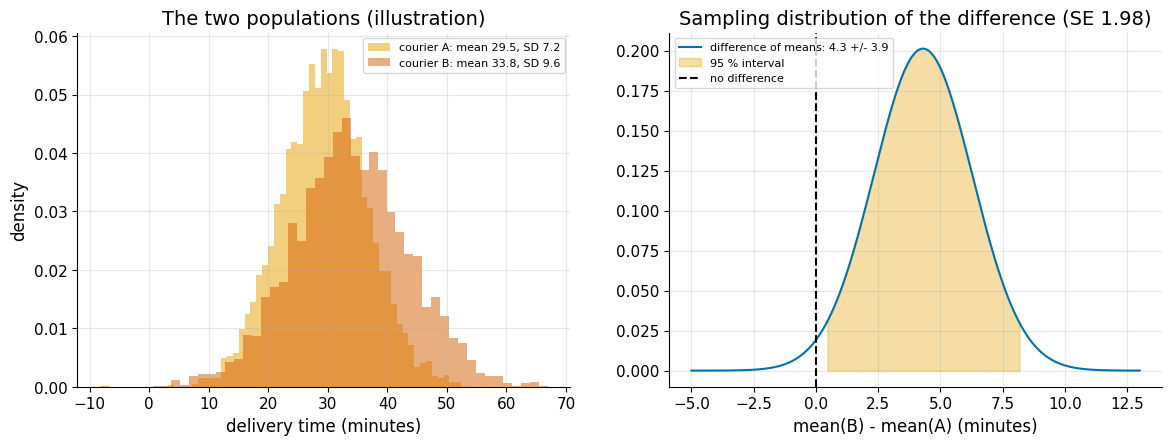

In [2]:
n_a, m_a, s_a = 40, 29.5, 7.2; n_b, m_b, s_b = 35, 33.8, 9.6
xa = rng.normal(m_a, s_a, 4000); xb = rng.normal(m_b, s_b, 4000)
se_d = np.sqrt(s_a**2 / n_a + s_b**2 / n_b); d_obs = m_b - m_a
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].hist(xa, bins=50, density=True, color=SIM, alpha=0.5, label=f"courier A: mean {m_a}, SD {s_a}"); axes[0].hist(xb, bins=50, density=True, color=HIGHLIGHT, alpha=0.5, label=f"courier B: mean {m_b}, SD {s_b}")
axes[0].set_xlabel("delivery time (minutes)"); axes[0].set_ylabel("density"); axes[0].set_title("The two populations (illustration)"); axes[0].legend(fontsize=8)
xs = np.linspace(-5, 13, 400); axes[1].plot(xs, stats.norm.pdf(xs, d_obs, se_d), color=MAIN, label=f"difference of means: {d_obs:.1f} +/- {1.96 * se_d:.1f}"); axes[1].fill_between(xs, 0, stats.norm.pdf(xs, d_obs, se_d), where=(xs >= d_obs - 1.96 * se_d) & (xs <= d_obs + 1.96 * se_d), color=SIM, alpha=0.35, label="95 % interval")
axes[1].axvline(0, color="black", linestyle="--", label="no difference"); axes[1].set_xlabel("mean(B) - mean(A) (minutes)"); axes[1].set_title(f"Sampling distribution of the difference (SE {se_d:.2f})"); axes[1].legend(fontsize=8)
plt.show()

### 7.2 Pairing: the same units measured twice
30 employees take a test before and after a training. The scatter of before against after lies close to the diagonal (strong correlation), so the *differences* are far less variable than the scores themselves, and a paired test is much more sensitive than an unpaired one.

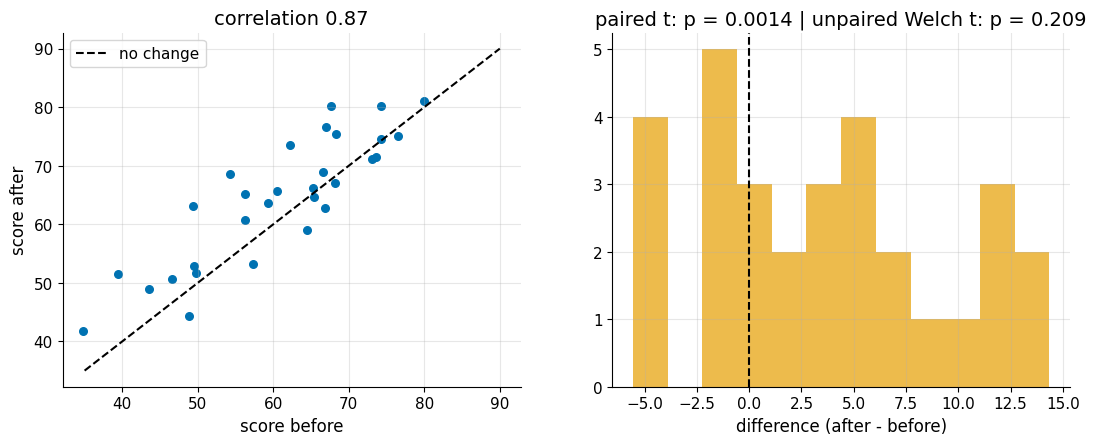

In [3]:
ability = rng.normal(60, 10, 30); before = ability + rng.normal(0, 4, 30); after = ability + 3 + rng.normal(0, 4, 30)
paired = stats.ttest_rel(after, before); unpaired = stats.ttest_ind(after, before, equal_var=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(before, after, color=MAIN, s=30); lim = [35, 90]; axes[0].plot(lim, lim, color="black", linestyle="--", label="no change"); axes[0].set_xlabel("score before"); axes[0].set_ylabel("score after"); axes[0].set_title(f"correlation {np.corrcoef(before, after)[0, 1]:.2f}"); axes[0].legend()
axes[1].hist(after - before, bins=12, color=SIM, alpha=0.7); axes[1].axvline(0, color="black", linestyle="--"); axes[1].set_xlabel("difference (after - before)"); axes[1].set_title(f"paired t: p = {paired.pvalue:.4f} | unpaired Welch t: p = {unpaired.pvalue:.3f}")
plt.show()
assert paired.pvalue < unpaired.pvalue

### 7.3 Observed against expected counts
A $3\times2$ table of plans against churn: observed counts, the counts expected under independence, and the contribution $(O-E)^2/E$ of each cell to the chi-square statistic.

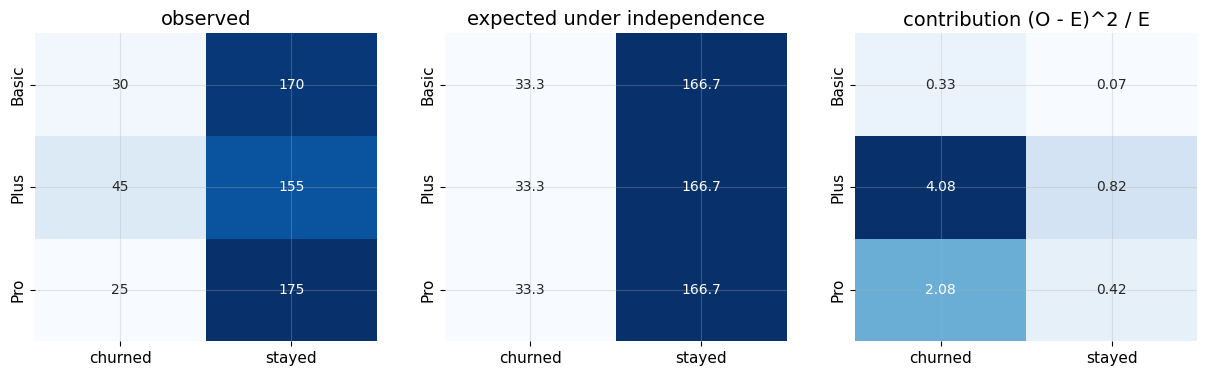

chi-square = 7.800, df = 2, p = 0.0202


In [4]:
obs = np.array([[30, 170], [45, 155], [25, 175]]); plans = ["Basic", "Plus", "Pro"]
chi2_t = stats.chi2_contingency(obs, correction=False); expected = chi2_t.expected_freq; contrib = (obs - expected) ** 2 / expected
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
for ax, mat, title, fmt in [(axes[0], obs, "observed", "d"), (axes[1], expected, "expected under independence", ".1f"), (axes[2], contrib, "contribution (O - E)^2 / E", ".2f")]:
    sns.heatmap(mat, annot=True, fmt=fmt, cmap="Blues", cbar=False, xticklabels=["churned", "stayed"], yticklabels=plans, ax=ax); ax.set_title(title)
plt.show()
print(f"chi-square = {chi2_t.statistic:.3f}, df = {chi2_t.dof}, p = {chi2_t.pvalue:.4f}")
assert np.isclose(contrib.sum(), chi2_t.statistic)

### 7.4 Between-group and within-group variation (ANOVA)
Three landing pages with the same within-group spread but different means. The $F$ statistic compares the spread of the group means (between) with the spread inside the groups (within): the larger the ratio, the stronger the evidence of a real difference.

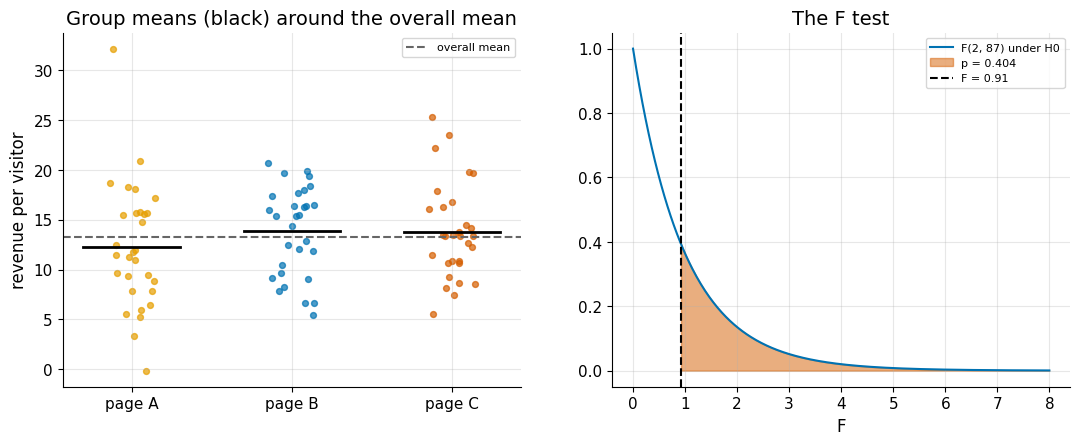

In [5]:
groups = {"A": rng.normal(12.0, 5, 30), "B": rng.normal(13.1, 5, 30), "C": rng.normal(14.3, 5, 30)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for (name, g), c in zip(groups.items(), [SIM, MAIN, HIGHLIGHT]):
    axes[0].scatter(np.full(30, ord(name) - 65) + rng.uniform(-0.15, 0.15, 30), g, s=18, color=c, alpha=0.7); axes[0].plot([ord(name) - 65 - 0.3, ord(name) - 65 + 0.3], [g.mean()] * 2, color="black", linewidth=2)
axes[0].axhline(np.concatenate(list(groups.values())).mean(), color=NEUTRAL, linestyle="--", label="overall mean"); axes[0].set_xticks([0, 1, 2]); axes[0].set_xticklabels(["page A", "page B", "page C"]); axes[0].set_ylabel("revenue per visitor"); axes[0].set_title("Group means (black) around the overall mean"); axes[0].legend(fontsize=8)
f_obs = stats.f_oneway(*groups.values()); ff = np.linspace(0, 8, 400)
axes[1].plot(ff, stats.f(2, 87).pdf(ff), color=MAIN, label="F(2, 87) under H0"); axes[1].fill_between(ff, 0, stats.f(2, 87).pdf(ff), where=ff >= f_obs.statistic, color=HIGHLIGHT, alpha=0.5, label=f"p = {f_obs.pvalue:.3f}"); axes[1].axvline(f_obs.statistic, color="black", linestyle="--", label=f"F = {f_obs.statistic:.2f}"); axes[1].set_xlabel("F"); axes[1].set_title("The F test"); axes[1].legend(fontsize=8)
plt.show()

## 8. 3D visuals

### 8.1 Static: power of the two-sample $t$-test over (effect size, group size)
Power of the two-sided Welch/pooled test ($\alpha=0.05$, equal group sizes) as a function of Cohen's $d$ and the number $n$ per group, computed with the noncentral $t$ distribution. The surface rises from the floor $\alpha=0.05$ (no effect) and saturates at 1: it shows how large the groups must be for a given effect, e.g. 64 per group for a medium effect ($d=0.5$) at 80 % power.

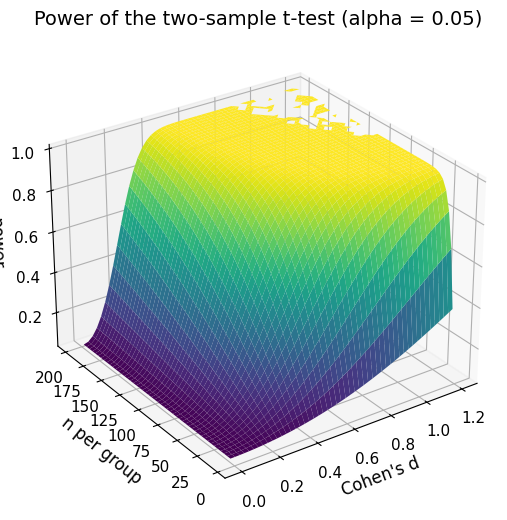

n per group for 80 % power at d = 0.5: 64 | at d = 0.2: 394


In [6]:
d_ax = np.linspace(0.0, 1.2, 50); n_ax = np.arange(5, 201, 4)
def power_t2(d, n):
    df = 2 * n - 2; tc = stats.t.ppf(0.975, df); nc = d * np.sqrt(n / 2); return stats.nct.sf(tc, df, nc) + stats.nct.cdf(-tc, df, nc)
PW = np.array([[power_t2(d, n) for d in d_ax] for n in n_ax]); Dg, Ng = np.meshgrid(d_ax, n_ax)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Dg, Ng, PW, cmap="viridis", edgecolor="none")
ax.set_xlabel("Cohen's d"); ax.set_ylabel("n per group"); ax.set_zlabel("power"); ax.set_title("Power of the two-sample t-test (alpha = 0.05)"); ax.view_init(elev=28, azim=-125)
plt.show()
n80 = next(n for n in range(2, 500) if power_t2(0.5, n) >= 0.8); print("n per group for 80 % power at d = 0.5:", n80, "| at d = 0.2:", next(n for n in range(2, 2000) if power_t2(0.2, n) >= 0.8))
assert n80 == 64 and abs(power_t2(0.0, 30) - 0.05) < 1e-6

### 8.2 Interactive Plotly version of 8.1
Hover to read the power for any effect size and group size.

In [7]:
fig = go.Figure(go.Surface(x=d_ax, y=n_ax, z=PW, colorscale="Viridis"))
fig.update_layout(title="Power of the two-sample t-test", width=760, height=560, scene=dict(xaxis_title="Cohen's d", yaxis_title="n per group", zaxis_title="power"))
fig.show()

### 8.3 Static: the chi-square p-value over (statistic, degrees of freedom)
The p-value of the chi-square test as a function of the statistic and the degrees of freedom: for a fixed statistic, more degrees of freedom (more cells) means a *larger* p-value (less surprising).

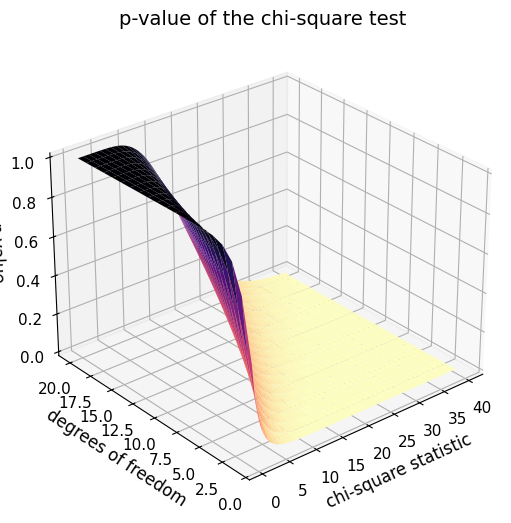

In [8]:
c_ax = np.linspace(0.5, 40, 80); df_ax = np.arange(1, 21)
Cg, DFg = np.meshgrid(c_ax, df_ax); Pv = stats.chi2.sf(Cg, DFg)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Cg, DFg, Pv, cmap="magma_r", edgecolor="none")
ax.set_xlabel("chi-square statistic"); ax.set_ylabel("degrees of freedom"); ax.set_zlabel("p-value"); ax.set_title("p-value of the chi-square test"); ax.view_init(elev=28, azim=-130)
plt.show()

## 9. Simulation vs theory

### 9.1 Welch versus pooled when variances differ
Two groups with the **same mean** (so $H_0$ is true) but unequal sizes and variances. The pooled $t$-test is correct only when $\sigma_1=\sigma_2$: when the small group has the large variance it rejects far too often; Welch holds the 5 % level.

In [9]:
def type1(n1, n2, s1, s2, reps=40_000):
    x = rng.normal(0, s1, (reps, n1)); y = rng.normal(0, s2, (reps, n2))
    return np.mean(stats.ttest_ind(x, y, axis=1, equal_var=True).pvalue < 0.05), np.mean(stats.ttest_ind(x, y, axis=1, equal_var=False).pvalue < 0.05)
rows = []
for label, args in [("equal sizes, equal SD", (30, 30, 5, 5)), ("equal sizes, SD 5 vs 15", (30, 30, 5, 15)), ("small group has the large SD", (10, 50, 15, 5)), ("large group has the large SD", (50, 10, 15, 5))]:
    pooled_rate, welch_rate = type1(*args); rows.append({"setting": label, "pooled t: Type I error": pooled_rate, "Welch t: Type I error": welch_rate})
t1 = pd.DataFrame(rows); print(t1.round(4).to_string(index=False))
assert t1.iloc[2, 1] > 0.12 and abs(t1.iloc[2, 2] - 0.05) < 0.008 and t1.iloc[3, 1] < 0.03

                     setting  pooled t: Type I error  Welch t: Type I error
       equal sizes, equal SD                  0.0486                 0.0485
     equal sizes, SD 5 vs 15                  0.0514                 0.0491
small group has the large SD                  0.2887                 0.0501
large group has the large SD                  0.0007                 0.0491


### 9.2 The $F$ statistic under the null follows the $F$ distribution
Generate 20,000 data sets with three groups of 30 and no true differences; the simulated $F$ values should match $F_{2,87}$ and 5 % should exceed the critical value.

In [10]:
fs = np.array([stats.f_oneway(*rng.normal(0, 5, (3, 30))).statistic for _ in range(20_000)])
crit = stats.f(2, 87).ppf(0.95)
print(f"share of F above the 5 % critical value {crit:.3f}: {np.mean(fs > crit):.4f} | mean of F {fs.mean():.3f} (theory {87 / 85:.3f}) | KS distance to F(2, 87): {stats.kstest(fs, stats.f(2, 87).cdf).statistic:.4f}")
assert abs(np.mean(fs > crit) - 0.05) < 0.006 and abs(fs.mean() - 87 / 85) < 0.03

share of F above the 5 % critical value 3.101: 0.0517 | mean of F 1.026 (theory 1.024) | KS distance to F(2, 87): 0.0050


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
a = rng.normal(29.5, 7.2, 40); b = rng.normal(33.8, 9.6, 35)
print("Welch t-test:", stats.ttest_ind(b, a, equal_var=False), "| pooled:", stats.ttest_ind(b, a))
print("from summary numbers: stats.ttest_ind_from_stats(33.8, 9.6, 35, 29.5, 7.2, 40, equal_var=False) ->", stats.ttest_ind_from_stats(33.8, 9.6, 35, 29.5, 7.2, 40, equal_var=False))
print("paired t-test: stats.ttest_rel(after, before) ->", stats.ttest_rel(after, before))
print("chi-square independence: stats.chi2_contingency(table) ->", round(chi2_t.statistic, 3), round(chi2_t.pvalue, 4), chi2_t.dof, "| goodness of fit: stats.chisquare(observed, expected) ->", stats.chisquare([89, 112, 98, 105, 94, 102], [100] * 6))
print("one-way ANOVA: stats.f_oneway(g1, g2, g3) ->", stats.f_oneway(*groups.values()))
print("Cramer's V from a table: sqrt(chi2 / (n min(r-1, c-1))) =", round(float(np.sqrt(chi2_t.statistic / (obs.sum() * min(obs.shape[0] - 1, obs.shape[1] - 1)))), 4))
print("Cohen's d: (mean1 - mean2) / pooled SD =", round((b.mean() - a.mean()) / np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)), 3))

Welch t-test: TtestResult(statistic=np.float64(3.0093637734754646), pvalue=np.float64(0.003695990588391142), df=np.float64(66.49161524697585)) | pooled: TtestResult(statistic=np.float64(3.0461795527174953), pvalue=np.float64(0.003224134304558358), df=np.float64(73.0))
from summary numbers: stats.ttest_ind_from_stats(33.8, 9.6, 35, 29.5, 7.2, 40, equal_var=False) -> Ttest_indResult(statistic=np.float64(2.169299648660303), pvalue=np.float64(0.03387102189210106))
paired t-test: stats.ttest_rel(after, before) -> TtestResult(statistic=np.float64(3.5198627538615903), pvalue=np.float64(0.0014468383892773406), df=np.int64(29))
chi-square independence: stats.chi2_contingency(table) -> 7.8 0.0202 2 | goodness of fit: stats.chisquare(observed, expected) -> Power_divergenceResult(statistic=np.float64(3.34), pvalue=np.float64(0.6477234887981782))
one-way ANOVA: stats.f_oneway(g1, g2, g3) -> F_onewayResult(statistic=np.float64(0.9146163601867411), pvalue=np.float64(0.40448774503834306))
Cramer's V f

## 11. Real-world worked examples

---
### Example 1 (main): do the two couriers deliver equally fast?

**Scenario.** Delivery times of two couriers: courier A, $n=40$ deliveries, mean **29.5** min, SD **7.2**; courier B, $n=35$ deliveries, mean **33.8** min, SD **9.6**. Test $H_0:\mu_A=\mu_B$ against the two-sided alternative at $\alpha=0.05$.

**Questions**
1. Compute the **Welch $t$ statistic**, its degrees of freedom and the **p-value**.
2. Give the 95 % **confidence interval for the difference** and **Cohen's $d$**.
3. Compare with the **pooled** test.
4. By simulation, what are the Type I error and power of the Welch test for this design?

### 11.1 By hand
**Q1.** Difference $=33.8-29.5=4.3$. $\mathrm{SE}=\sqrt{\frac{7.2^2}{40}+\frac{9.6^2}{35}}=\sqrt{1.296+2.633}=1.982$. $t=4.3/1.982=\mathbf{2.17}$. Degrees of freedom $\nu=\dfrac{(3.929)^2}{\frac{1.296^2}{39}+\frac{2.633^2}{34}}=\dfrac{15.44}{0.0431+0.2039}=\mathbf{62.5}$; the two-sided p-value is about $\mathbf{0.034}<0.05$: **reject** $H_0$.

**Q2.** $t_{62.5,0.975}\approx1.999$: $4.3\pm1.999\times1.982=\mathbf{(0.34,\ 8.26)}$ minutes. Pooled SD $s_p=\sqrt{\frac{39(51.84)+34(92.16)}{73}}=8.40$, so $d=4.3/8.40=\mathbf{0.51}$ (a medium effect).

**Q3.** The pooled test uses $\mathrm{SE}_p=8.40\sqrt{1/40+1/35}=1.945$ and $\nu=73$: $t=2.21$, $p=0.030$: very close to Welch because the variances are not very unequal.

**Q4.** By simulation (below).

In [12]:
r_w = stats.ttest_ind_from_stats(33.8, 9.6, 35, 29.5, 7.2, 40, equal_var=False); r_p = stats.ttest_ind_from_stats(33.8, 9.6, 35, 29.5, 7.2, 40, equal_var=True)
v1, v2 = 7.2**2 / 40, 9.6**2 / 35; df_w = (v1 + v2) ** 2 / (v1**2 / 39 + v2**2 / 34); se_w = np.sqrt(v1 + v2)
tcrit = stats.t.ppf(0.975, df_w); ci_d = (4.3 - tcrit * se_w, 4.3 + tcrit * se_w)
sp = np.sqrt((39 * 7.2**2 + 34 * 9.6**2) / 73); d_c = 4.3 / sp
print(f"Q1: t = {r_w.statistic:.3f}, df = {df_w:.1f}, p = {r_w.pvalue:.4f} | Q2: 95 % CI for the difference ({ci_d[0]:.2f}, {ci_d[1]:.2f}), Cohen's d = {d_c:.3f} | Q3: pooled t = {r_p.statistic:.3f}, p = {r_p.pvalue:.4f}")

Q1: t = 2.169, df = 62.5, p = 0.0339 | Q2: 95 % CI for the difference (0.34, 8.26), Cohen's d = 0.512 | Q3: pooled t = 2.211, p = 0.0302


### 11.2 In code with `scipy`, and the asserts

In [13]:
assert abs(r_w.statistic - 2.17) < 0.01 and abs(df_w - 62.5) < 0.3 and abs(r_w.pvalue - 0.034) < 0.002
assert abs(ci_d[0] - 0.34) < 0.03 and abs(ci_d[1] - 8.26) < 0.03 and abs(d_c - 0.512) < 0.005 and r_p.pvalue < r_w.pvalue
assert (r_w.pvalue < 0.05) == (ci_d[0] > 0)                      # test and interval agree
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Take the two groups as the truth and simulate 100,000 studies: the Type I error when both couriers have the *same* mean (the average of the two) and the power when they differ as observed.

In [14]:
sg = np.random.default_rng(31); R = 60_000
def reject_rate(mu_a, mu_b):
    x = sg.normal(mu_a, 7.2, (R, 40)); y = sg.normal(mu_b, 9.6, (R, 35)); return np.mean(stats.ttest_ind(y, x, axis=1, equal_var=False).pvalue < 0.05)
t1_rate, power_obs = reject_rate(31.65, 31.65), reject_rate(29.5, 33.8)
print(f"Type I error of the Welch test (equal means): {t1_rate:.4f} | power when the true difference is 4.3 minutes: {power_obs:.4f}")
a_s = sg.normal(29.5, 7.2, (60_000, 40)).mean(axis=1); b_s = sg.normal(33.8, 9.6, (60_000, 35)).mean(axis=1)
print(f"sampling distribution of the difference: mean {(b_s - a_s).mean():.3f}, SD {(b_s - a_s).std():.3f} (theory SE {se_w:.3f})")
assert abs(t1_rate - 0.05) < 0.005 and 0.5 < power_obs < 0.7 and abs((b_s - a_s).std() - se_w) < 0.03

Type I error of the Welch test (equal means): 0.0498 | power when the true difference is 4.3 minutes: 0.5725
sampling distribution of the difference: mean 4.299, SD 1.971 (theory SE 1.982)


### 11.4 Plots with the regions shaded

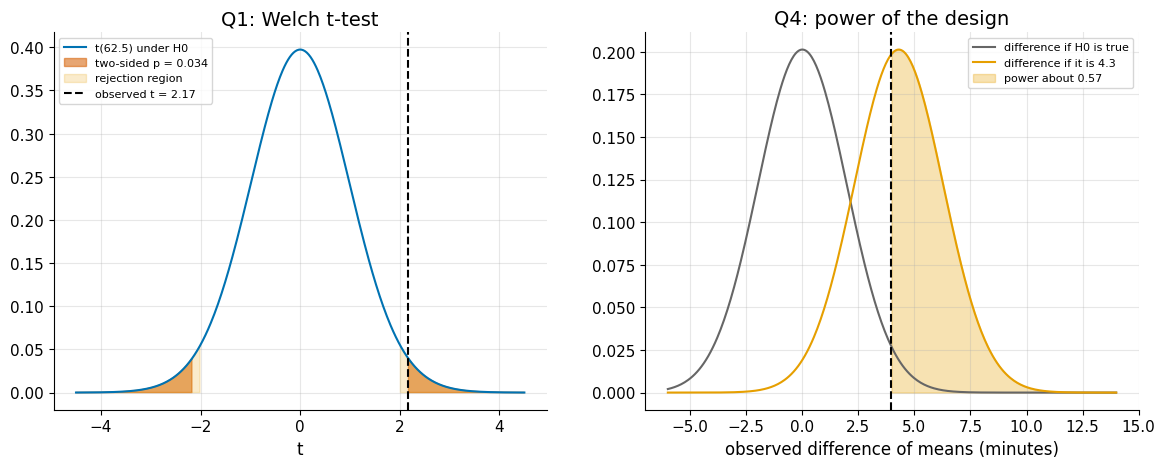

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
tt = np.linspace(-4.5, 4.5, 500); dist = stats.t(df_w)
axes[0].plot(tt, dist.pdf(tt), color=MAIN, label=f"t({df_w:.1f}) under H0"); axes[0].fill_between(tt, 0, dist.pdf(tt), where=np.abs(tt) >= abs(r_w.statistic), color=HIGHLIGHT, alpha=0.55, label=f"two-sided p = {r_w.pvalue:.3f}"); axes[0].fill_between(tt, 0, dist.pdf(tt), where=np.abs(tt) >= tcrit, color=SIM, alpha=0.2, label="rejection region")
axes[0].axvline(r_w.statistic, color="black", linestyle="--", label=f"observed t = {r_w.statistic:.2f}"); axes[0].set_xlabel("t"); axes[0].set_title("Q1: Welch t-test"); axes[0].legend(fontsize=8)
dd = np.linspace(-6, 14, 400); axes[1].plot(dd, stats.norm.pdf(dd, 0, se_w), color=NEUTRAL, label="difference if H0 is true"); axes[1].plot(dd, stats.norm.pdf(dd, 4.3, se_w), color=SIM, label="difference if it is 4.3")
axes[1].fill_between(dd, 0, stats.norm.pdf(dd, 4.3, se_w), where=dd >= tcrit * se_w, color=SIM, alpha=0.3, label=f"power about {power_obs:.2f}"); axes[1].axvline(tcrit * se_w, color="black", linestyle="--"); axes[1].set_xlabel("observed difference of means (minutes)"); axes[1].set_title("Q4: power of the design"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- Courier B is **4.3 minutes slower** on average, and the Welch test gives $t=2.17$ on 62.5 degrees of freedom, **p = 0.034**: we reject equality at the 5 % level. The 95 % interval for the difference is **0.3 to 8.3 minutes**, wide because only 40 and 35 deliveries were timed: the data show that B is slower, but not by how much. Cohen's $d=0.51$ is a **medium** effect.
- The pooled test (p = 0.030) agrees here because the two standard deviations (7.2 and 9.6) are not very different. When they differ *and* the small group is the noisy one the pooled test breaks (Section 9.1): its Type I error reaches **29 %** instead of 5 %, while Welch stays at 5.0 %.
- The Welch test holds its level in this design (Type I error 5.0 %), but with a true difference of 4.3 minutes it detects it only **57 %** of the time: a significant result here is somewhat lucky.
- **Decision.** Treat courier B as probably slower (about 4 minutes) and investigate the reason, but do not penalise anyone on this evidence alone: time about 100 more deliveries each, which would narrow the interval to about $\pm2$ minutes and make the power for a 4-minute difference well above 80 %.

---
### Example 2: does the plan type affect churn? (chi-square test of independence)

**Scenario.** Of 200 customers on each plan, the numbers who **churned** in a year were **30** (Basic), **45** (Plus) and **25** (Pro).

**Questions**
1. Compute the expected counts, the chi-square statistic, the degrees of freedom and the p-value.
2. Measure the strength of the association (**Cramer's V**).
3. Which cells contribute most?

### 11.6 By hand
**Q1.** Total churned $=100$ out of 600 (16.7 %), so each plan is expected to lose $200\times100/600=33.33$ and keep $166.67$. $\chi^2=\sum\frac{(O-E)^2}{E}$: Basic: $\frac{3.33^2}{33.33}+\frac{3.33^2}{166.67}=0.333+0.067=0.400$; Plus: $\frac{11.67^2}{33.33}+\frac{11.67^2}{166.67}=4.083+0.817=4.900$; Pro: $\frac{8.33^2}{33.33}+\frac{8.33^2}{166.67}=2.083+0.417=2.500$. Total $\chi^2=\mathbf{7.80}$ with $(3-1)(2-1)=2$ degrees of freedom; $p=e^{-7.8/2}=\mathbf{0.0202}$.

**Q2.** $V=\sqrt{7.8/(600\times1)}=\mathbf{0.114}$: a weak association.

**Q3.** The **Plus** plan contributes 4.9 of the 7.8 (it churns more than expected), then **Pro** (2.5, it churns less).

expected counts:
[[ 33.33 166.67]
 [ 33.33 166.67]
 [ 33.33 166.67]]
chi-square = 7.800, df = 2, p = 0.0202, Cramer's V = 0.114
contributions by cell:
[[0.333 0.067]
 [4.083 0.817]
 [2.083 0.417]]


permutation check: share of shuffled tables with chi-square >= 7.8 = 0.0220 (p-value 0.0202)


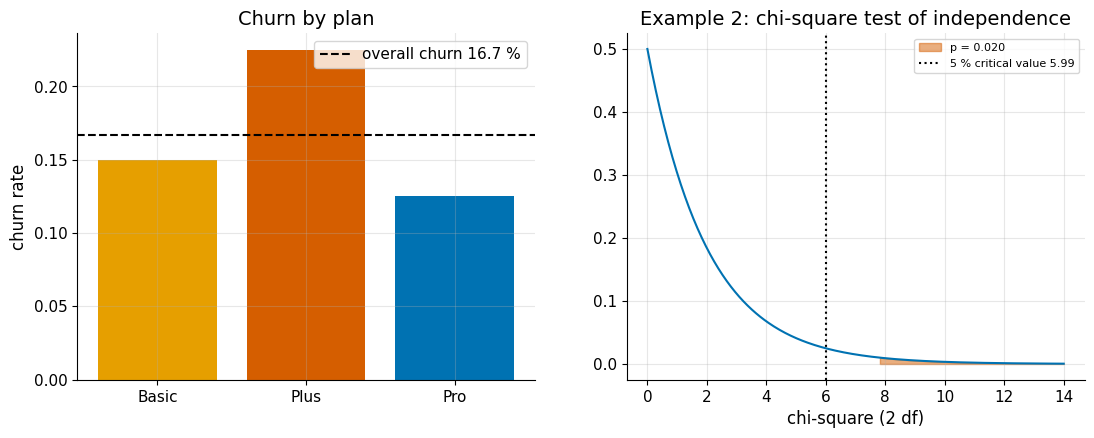

In [16]:
tab = np.array([[30, 170], [45, 155], [25, 175]]); res2 = stats.chi2_contingency(tab, correction=False)
V = np.sqrt(res2.statistic / (tab.sum() * min(tab.shape[0] - 1, tab.shape[1] - 1))); contrib2 = (tab - res2.expected_freq) ** 2 / res2.expected_freq
print(f"expected counts:\n{res2.expected_freq.round(2)}\nchi-square = {res2.statistic:.3f}, df = {res2.dof}, p = {res2.pvalue:.4f}, Cramer's V = {V:.3f}\ncontributions by cell:\n{contrib2.round(3)}")
assert np.isclose(res2.statistic, 7.8) and np.isclose(res2.pvalue, np.exp(-3.9)) and res2.dof == 2 and abs(V - 0.114) < 0.001
sim2 = np.random.default_rng(5)
def one_perm():
    pm = sim2.permutation(np.repeat([0, 1], [100, 500]))                      # shuffle who churned among the 600 customers
    return stats.chi2_contingency(np.array([np.bincount(pm[i * 200:(i + 1) * 200], minlength=2) for i in range(3)]), correction=False).statistic
shuffled = [one_perm() for rep_ in range(5000)]
print(f"permutation check: share of shuffled tables with chi-square >= 7.8 = {np.mean(np.array(shuffled) >= 7.8):.4f} (p-value {res2.pvalue:.4f})")
assert abs(np.mean(np.array(shuffled) >= 7.8) - res2.pvalue) < 0.01
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(plans, tab[:, 0] / 200, color=[SIM, HIGHLIGHT, MAIN]); axes[0].axhline(100 / 600, color="black", linestyle="--", label="overall churn 16.7 %"); axes[0].set_ylabel("churn rate"); axes[0].set_title("Churn by plan"); axes[0].legend()
xs = np.linspace(0, 14, 300); axes[1].plot(xs, stats.chi2(2).pdf(xs), color=MAIN); axes[1].fill_between(xs, 0, stats.chi2(2).pdf(xs), where=xs >= 7.8, color=HIGHLIGHT, alpha=0.5, label=f"p = {res2.pvalue:.3f}"); axes[1].axvline(stats.chi2(2).ppf(0.95), color="black", linestyle=":", label="5 % critical value 5.99"); axes[1].set_xlabel("chi-square (2 df)"); axes[1].set_title("Example 2: chi-square test of independence"); axes[1].legend(fontsize=8)
plt.show()

### 11.7 Interpretation and decision (Example 2)
- Under independence each plan would lose 33 of 200 customers, but the **Plus plan lost 45 and the Pro plan only 25**: $\chi^2=7.8$ on 2 degrees of freedom, **p = 0.020**. A permutation check (shuffling who churned) gives the same answer, 0.022, so the approximation is accurate here.
- The association is **real but weak**: Cramer's $V=0.11$. The Plus plan accounts for 4.9 of the 7.8 chi-square points, the Pro plan for 2.5.
- **Decision.** Churn depends on the plan, mainly because Plus customers leave more than expected. Look at the Plus plan (price, features, onboarding) first; do not conclude that Pro *causes* loyalty (customers who choose Pro may be different), and re-test with the next year's data.

---
### Example 3: three landing pages (one-way ANOVA)

**Scenario.** Revenue per visitor (dollars) for three landing pages, 30 visitors each: means **12.0**, **13.1** and **14.3**, common within-page SD about **5**.

**Questions**
1. Build the ANOVA table ($SSB$, $SSW$, $F$) from the summary numbers and find the p-value.
2. How much of the variation is explained ($\eta^2$)?
3. What is the power of this design to detect the observed pattern, and how large must the groups be for 80 % power?

### 11.8 By hand
**Q1.** Overall mean $=(12.0+13.1+14.3)/3=13.133$. $SSB=30[(12-13.133)^2+(13.1-13.133)^2+(14.3-13.133)^2]=30(1.284+0.001+1.361)=79.4$, $df_B=2$, $MSB=39.7$. $SSW=(N-k)s^2=87\times25=2175$, $MSW=25$. $F=39.7/25=\mathbf{1.59}$ with $(2,87)$ df; $p\approx\mathbf{0.21}$.

**Q2.** $\eta^2=SSB/SST=79.4/2254.4=\mathbf{0.035}$ (3.5 % of the variation).

**Q3.** The power is computed from the noncentral $F$ distribution (about 0.33); about **93 visitors per page** would be needed for 80 %.

SSB = 79.4, SSW = 2175, MSB = 39.70, MSW = 25.0, F = 1.588, p = 0.2102, eta^2 = 0.0352 | Cohen's f^2 = 0.0353, power = 0.328, n per page for 80 % power = 93


simulated power of the F test with n = 30 per page: 0.317 (noncentral F: 0.328)
for two groups F = t^2: F = 14.5421, t^2 = 14.5421


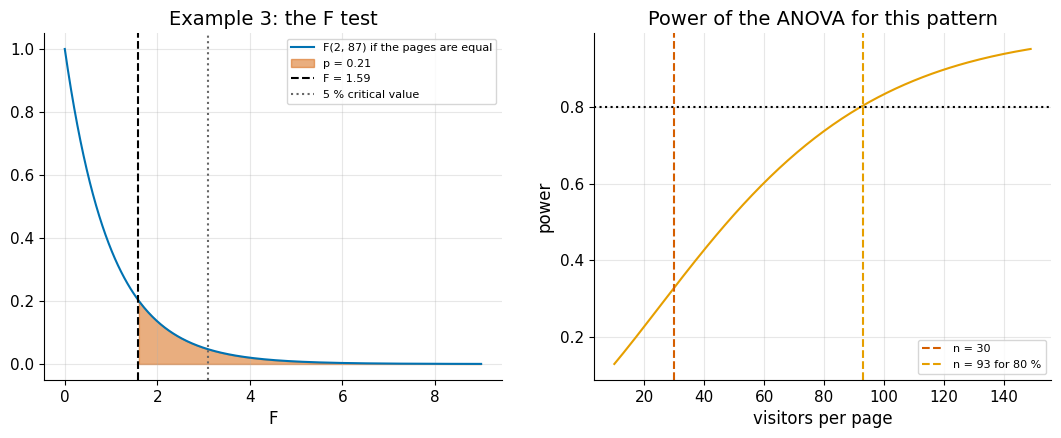

In [17]:
mus, nj, sd = np.array([12.0, 13.1, 14.3]), 30, 5.0
gm = mus.mean(); ssb = nj * ((mus - gm) ** 2).sum(); ssw = (3 * nj - 3) * sd**2; msb, msw = ssb / 2, ssw / (3 * nj - 3)
F = msb / msw; pF = stats.f(2, 3 * nj - 3).sf(F); eta2 = ssb / (ssb + ssw)
def power_F(n_per, cohen_f2):
    k, dfw = 3, 3 * n_per - 3; ncp = n_per * k * cohen_f2; return stats.ncf.sf(stats.f(k - 1, dfw).ppf(0.95), k - 1, dfw, ncp)
f2 = ((mus - gm) ** 2).mean() / sd**2                       # Cohen's f squared
pw_F = power_F(30, f2); n80F = next(n for n in range(5, 1000) if power_F(n, f2) >= 0.8)
print(f"SSB = {ssb:.1f}, SSW = {ssw:.0f}, MSB = {msb:.2f}, MSW = {msw:.1f}, F = {F:.3f}, p = {pF:.4f}, eta^2 = {eta2:.4f} | Cohen's f^2 = {f2:.4f}, power = {pw_F:.3f}, n per page for 80 % power = {n80F}")
assert abs(ssb - 79.4) < 0.3 and abs(F - 1.59) < 0.02 and abs(pF - 0.21) < 0.01 and abs(eta2 - 0.035) < 0.002
sim3 = np.random.default_rng(3); rej = np.mean([stats.f_oneway(*[sim3.normal(m, 5, 30) for m in mus]).pvalue < 0.05 for _ in range(6000)])
print(f"simulated power of the F test with n = 30 per page: {rej:.3f} (noncentral F: {pw_F:.3f})"); assert abs(rej - pw_F) < 0.02
two = [sim3.normal(12, 5, 30), sim3.normal(14.3, 5, 30)]; print(f"for two groups F = t^2: F = {stats.f_oneway(*two).statistic:.4f}, t^2 = {stats.ttest_ind(*two).statistic ** 2:.4f}")
assert np.isclose(stats.f_oneway(*two).statistic, stats.ttest_ind(*two).statistic ** 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); ff = np.linspace(0, 9, 400)
axes[0].plot(ff, stats.f(2, 87).pdf(ff), color=MAIN, label="F(2, 87) if the pages are equal"); axes[0].fill_between(ff, 0, stats.f(2, 87).pdf(ff), where=ff >= F, color=HIGHLIGHT, alpha=0.5, label=f"p = {pF:.2f}"); axes[0].axvline(F, color="black", linestyle="--", label=f"F = {F:.2f}"); axes[0].axvline(stats.f(2, 87).ppf(0.95), color=NEUTRAL, linestyle=":", label="5 % critical value"); axes[0].set_xlabel("F"); axes[0].set_title("Example 3: the F test"); axes[0].legend(fontsize=8)
nn_ = np.arange(10, 150); axes[1].plot(nn_, [power_F(k_, f2) for k_ in nn_], color=SIM); axes[1].axhline(0.8, color="black", linestyle=":"); axes[1].axvline(30, color=HIGHLIGHT, linestyle="--", label="n = 30"); axes[1].axvline(n80F, color=SIM, linestyle="--", label=f"n = {n80F} for 80 %"); axes[1].set_xlabel("visitors per page"); axes[1].set_ylabel("power"); axes[1].set_title("Power of the ANOVA for this pattern"); axes[1].legend(fontsize=8)
plt.show()

### 11.9 Interpretation and decision (Example 3)
- The page means 12.0, 13.1 and 14.3 look different, but with a within-page SD of 5 and only 30 visitors per page the ANOVA gives $F=1.59$ and **p = 0.21**: the data are consistent with all three pages being equal. The pages explain only **3.5 %** of the variation ($\eta^2=0.035$).
- **The design is underpowered:** if the means really are 12.0, 13.1 and 14.3 the test would detect it only **33 %** of the time (simulation 32 %); about **93 visitors per page** are needed for 80 %. The negative result therefore says little.
- For two groups the ANOVA is the same as the $t$-test: $F=t^2$ (14.54 in both).
- **Decision.** Do not pick page C on this evidence; extend the test to about 100 visitors per page (or accept a larger minimum effect), and plan the follow-up comparisons before looking at the data (06_06).

## 12. Where it is used

### Statistics
- **Experiments and observational studies:** comparison of treatments (two-sample and paired $t$, ANOVA), association tests in tables (chi-square, Fisher), model tests (the $F$ test in regression is the same ratio of variances).
- **Quality and reliability:** comparing suppliers, machines or shifts; goodness-of-fit checks of assumed distributions (chi-square, KS in 06_05).

### Data science
- **A/B and A/B/n tests** (06_07): Welch $t$ for revenue per user, chi-square or $z$ for conversion; ANOVA for several variants; paired tests for before/after on the same users.
- **Reporting and monitoring:** is a segment's metric different, did a drift in a categorical feature occur (chi-square on category counts).

### ML and AI
- **Comparing models and configurations:** paired $t$ on per-fold or per-example scores, McNemar's test on disagreements between two classifiers, ANOVA-style comparisons of many hyperparameter settings (with correction, 06_06).
- **Fairness and data checks:** chi-square tests of independence between predictions and a protected attribute; goodness-of-fit tests of label distributions in train and test sets.

## 13. Common pitfalls and misconceptions

- **Using the pooled $t$-test when variances and sizes differ** inflates the Type I error (9.1); make Welch the default.
- **Treating paired data as independent** loses power; treating independent data as paired is wrong. Decide from the design, not from the data.
- **Ignoring dependence:** repeated measures on the same user, clustered data and time series break all of these tests (05_08, design effects).
- **Chi-square with small expected counts** (below 5) is inaccurate; use Fisher's exact test or merge categories. Never apply it to percentages instead of counts.
- **A significant ANOVA does not say which groups differ,** and a non-significant one does not prove equality; follow up with corrected pairwise comparisons (06_06) and look at intervals.
- **Running many pairwise $t$-tests instead of one ANOVA** inflates the false-positive rate (5.6).
- **Normality is about the sampling distribution of the mean,** not of every observation: for large samples the tests work for skewed data, but for small skewed samples use permutation or rank tests (06_05).
- **Confusing "no significant difference" with "equivalent":** equivalence needs its own test or an interval inside a margin.

## 14. Exercises

1. Eight athletes' sprint times (s) before and after training are: before 12.1, 11.8, 12.5, 12.0, 12.9, 11.6, 12.3, 12.7; after 11.8, 11.6, 12.2, 12.0, 12.4, 11.5, 12.1, 12.3. Test whether training changed the mean time (paired $t$-test), and compare with the unpaired Welch test.
2. A die gives the counts 22, 17, 12, 19, 24, 26 over 120 rolls. Test fairness with the chi-square goodness-of-fit test.
3. Four teachers' classes have exam means 71, 74, 70, 78 (each class $n=25$, common SD 10). Compute $F$ and its p-value from the summary numbers. Is there evidence of a difference?
4. Show that for two groups the pooled $t$-test and the one-way ANOVA give the same p-value, with $F=t^2$.
5. Two groups have means 100 and 106, SD 15 in both. How many observations per group give 80 % power at the 5 % level (two-sided)? Check with the noncentral $t$.
6. (Harder) Simulate 10,000 data sets from two Exponential(mean 10) samples of size 15 and compare the Type I error rates of the Welch $t$-test and the Mann-Whitney test (06_05).

Solutions are at the end.

## 15. Summary table

| Question | Test | Statistic and distribution | Assumes |
|---|---|---|---|
| two group means | Welch $t$ | $\frac{\bar x_1-\bar x_2}{\sqrt{s_1^2/n_1+s_2^2/n_2}}$, Satterthwaite $\nu$ | independence, roughly Normal means |
| same units twice | paired $t$ | $\bar d/(s_d/\sqrt n)$, $n-1$ df | differences roughly Normal |
| counts vs a model | chi-square GOF | $\sum(O-E)^2/E$, $K-1$ df | $E\ge5$ |
| two categorical variables | chi-square independence | same, $(r-1)(c-1)$ df | $E\ge5$ |
| several means | one-way ANOVA | $F=MSB/MSW$, $(k-1,N-k)$ df | equal variances |
| effect sizes | $d$, $V$, $\eta^2$ | 0.2 / 0.5 / 0.8 for $d$ | |
| `scipy` | `ttest_ind`, `ttest_rel`, `chi2_contingency`, `chisquare`, `f_oneway` | | |

## Solutions

In [18]:
bef = np.array([12.1, 11.8, 12.5, 12.0, 12.9, 11.6, 12.3, 12.7]); aft = np.array([11.8, 11.6, 12.2, 12.0, 12.4, 11.5, 12.1, 12.3])
pr, ur = stats.ttest_rel(bef, aft), stats.ttest_ind(bef, aft, equal_var=False)
print(f"1: mean difference {np.mean(bef - aft):.3f}, paired t = {pr.statistic:.3f}, p = {pr.pvalue:.4f} | Welch t = {ur.statistic:.3f}, p = {ur.pvalue:.3f}")
cg = stats.chisquare([22, 17, 12, 19, 24, 26], [20] * 6); print(f"2: chi-square = {cg.statistic:.2f}, df = 5, p = {cg.pvalue:.3f}")
means = np.array([71, 74, 70, 78]); ssb3 = 25 * ((means - means.mean()) ** 2).sum(); F3 = (ssb3 / 3) / 100; print(f"3: SSB = {ssb3:.0f}, MSB = {ssb3 / 3:.1f}, MSW = 100, F = {F3:.3f}, p = {stats.f(3, 96).sf(F3):.4f}")
x4 = rng.normal(0, 1, 30); y4 = rng.normal(0.5, 1, 30); print(f"4: pooled t^2 = {stats.ttest_ind(x4, y4).statistic ** 2:.4f}, ANOVA F = {stats.f_oneway(x4, y4).statistic:.4f}; p-values {stats.ttest_ind(x4, y4).pvalue:.5f} and {stats.f_oneway(x4, y4).pvalue:.5f}")
n5 = next(n for n in range(2, 500) if power_t2(6 / 15, n) >= 0.8); print(f"5: d = 0.4 -> {n5} per group for 80 % power (the normal formula gives {math.ceil(2 * ((1.96 + 0.8416) / 0.4) ** 2)})")
e1, e2 = rng.exponential(10, (10_000, 15)), rng.exponential(10, (10_000, 15))
rw = np.mean(stats.ttest_ind(e1, e2, axis=1, equal_var=False).pvalue < 0.05); rm = np.mean([stats.mannwhitneyu(a_, b_).pvalue < 0.05 for a_, b_ in zip(e1[:3000], e2[:3000])])
print(f"6: Type I error for Exponential data, n = 15 per group: Welch {rw:.4f}, Mann-Whitney {rm:.4f}")
assert abs(F3 - 3.0) < 0.5 and n5 == 100 and abs(stats.ttest_ind(x4, y4).statistic ** 2 - stats.f_oneway(x4, y4).statistic) < 1e-9

1: mean difference 0.250, paired t = 4.410, p = 0.0031 | Welch t = 1.277, p = 0.224
2: chi-square = 6.50, df = 5, p = 0.261
3: SSB = 969, MSB = 322.9, MSW = 100, F = 3.229, p = 0.0258
4: pooled t^2 = 2.1154, ANOVA F = 2.1154; p-values 0.15122 and 0.15122
5: d = 0.4 -> 100 per group for 80 % power (the normal formula gives 99)


6: Type I error for Exponential data, n = 15 per group: Welch 0.0416, Mann-Whitney 0.0480


**1.** The mean improvement is 0.25 s. The **paired** test gives $t=4.41$, **p = 0.003**: training clearly lowered the times. The **unpaired** Welch test gives only $t=1.28$, p = 0.22: the athletes differ a lot among themselves, which swamps the improvement unless each athlete is compared with his or her own earlier time.

**2.** $\chi^2=6.50$ on 5 degrees of freedom, **p = 0.26**: no evidence that the die is unfair (the 5 % critical value is 11.07).

**3.** $SSB=25\sum(\bar x_j-\bar x)^2=969$, $MSB=323$, $MSW=100$: $F=3.23$ on $(3,96)$ df, **p = 0.026**: evidence of a difference among the classes.

**4.** For two groups $F=t^2$ (2.1154 in both) and the p-values coincide (0.1512).

**5.** $d=6/15=0.4$: the noncentral $t$ gives **100 per group** for 80 % power (the normal formula $2\big((1.96+0.84)/0.4\big)^2=99$).

**6.** For skewed Exponential data with 15 per group the Welch test has a Type I error of 4.2 % and the Mann-Whitney test 4.8 %: both near 5 %, with the rank test slightly closer.